# Laboratorio — Robot de entregas en un almacén

A partir de la **imagen**, construye el MDP y resuélvelo con **Value Iteration** y **Policy Iteration**.

![Mundo del ejercicio](https://drive.google.com/uc?export=view&id=1_sJaD57gHuiz1joEgl4B-u0aDy8jtMDo)



## Convención y notación

$$
s=(row,col)
$$

$$
T(s,a,s')=P(s'\mid s,a)
$$

$$
R(s)
$$

Para Value Iteration:

$$
V_{k+1}(s)
=
R(s)
+
\gamma
\max_a
\sum_{s'}T(s,a,s')V_k(s')
$$

Para Policy Evaluation:

$$
V_{k+1}^{\pi}(s)
=
R(s)
+
\gamma
\sum_{s'}T(s,\pi(s),s')V_k^\pi(s')
$$

### Acciones

```python
UP    = (-1, 0)
DOWN  = ( 1, 0)
LEFT  = ( 0,-1)
RIGHT = ( 0, 1)
```



## Reglas del mundo

El grid tiene **5 filas × 6 columnas**.

### Estados especiales

A partir de la imagen identifica:

- `START`
- estanterías / paredes;
- zona de entrega `+10` (**terminal**);
- estación de carga `+2` (**terminal**);
- peligro mortal `-10` (**terminal**);
- peligros `-3` (**no terminales**);
- celdas de piso resbaloso.

### Recompensa

Usamos la convención del notebook de clase, es decir, **\(R(s)\)**:

- entrega: `+10`;
- carga: `+2`;
- peligro mortal: `-10`;
- peligro: `-3`;
- cualquier otro estado transitable: `-1` (costo por paso).

### Dinámica

La transición depende del **estado actual**:

**Piso normal**

$$
P(\text{dirección elegida})=0.90
$$

$$
P(\text{desviación izquierda})=0.05
$$

$$
P(\text{desviación derecha})=0.05
$$

**Piso resbaloso**

$$
P(\text{dirección elegida})=0.60
$$

$$
P(\text{desviación izquierda})=0.20
$$

$$
P(\text{desviación derecha})=0.20
$$

Si el movimiento sale del grid o golpea una estantería, el robot **permanece en el mismo estado**.

Usa:

$$
\gamma=0.9,\qquad \theta=10^{-4}
$$



## Parte 1 — Modela el MDP

Completa la clase `WarehouseMDP`.

La parte importante no es escribir muchas líneas de código: es traducir correctamente la imagen a:

- estados;
- acciones;
- recompensas;
- terminales;
- obstáculos;
- tipos de piso;
- función de transición.


In [1]:
import numpy as np

class WarehouseMDP:
    def __init__(self, living_reward=-1.0, gamma=0.9, p_slip_intended=0.60):
        self.height = 5
        self.width = 6

        # Traducción de la imagen (fila, columna)
        self.start = (0, 0)
        self.walls = {(0, 3), (1, 1), (2, 4), (4, 2)}           # estanterías
        self.slippery_states = {(1, 2), (2, 1), (3, 3)}         # piso resbaloso

        self.terminal_states = {
            (0, 5): +10.0,   # zona de entrega
            (2, 2): +2.0,    # estación de carga
            (3, 5): -10.0,   # peligro mortal
        }

        self.danger_states = {
            (1, 4): -3.0,    # peligro (no terminal)
            (4, 1): -3.0,    # peligro (no terminal)
        }

        self.living_reward = living_reward
        self.gamma = gamma

        # Probabilidades de la dinámica: (deseada, desvío izq., desvío der.)
        self.p_normal = (0.90, 0.05, 0.05)
        p_side = (1.0 - p_slip_intended) / 2
        self.p_slippery = (p_slip_intended, p_side, p_side)

        self.actions = [
            (-1, 0),  # UP
            ( 1, 0),  # DOWN
            ( 0,-1),  # LEFT
            ( 0, 1),  # RIGHT
        ]

    def is_valid_state(self, state):
        r, c = state
        return 0 <= r < self.height and 0 <= c < self.width and state not in self.walls

    def states(self):
        return [(r, c) for r in range(self.height) for c in range(self.width)
                if self.is_valid_state((r, c))]

    def is_terminal(self, state):
        return state in self.terminal_states

    def get_reward(self, state):
        # R(s): recompensa del estado actual
        if state in self.terminal_states:
            return self.terminal_states[state]
        if state in self.danger_states:
            return self.danger_states[state]
        return self.living_reward

    @staticmethod
    def _left_of(action):
        dr, dc = action
        return (-dc, dr)      # giro de 90° a la izquierda respecto a la dirección elegida

    @staticmethod
    def _right_of(action):
        dr, dc = action
        return (dc, -dr)      # giro de 90° a la derecha

    def _move(self, state, action):
        nxt = (state[0] + action[0], state[1] + action[1])
        # borde o estantería -> se queda en el mismo estado
        return nxt if self.is_valid_state(nxt) else state

    def get_transition_probs(self, state, action):
        """
        Devuelve:
            [(next_state, probability), ...]

        Recuerda:
        - las probabilidades dependen de si 'state' es resbaloso;
        - si golpea pared/borde, next_state = state.
        """
        if self.is_terminal(state):
            return [(state, 1.0)]      # terminal absorbente

        p_int, p_left, p_right = (self.p_slippery if state in self.slippery_states
                                  else self.p_normal)
        outcomes = {}
        for a, p in [(action, p_int),
                     (self._left_of(action), p_left),
                     (self._right_of(action), p_right)]:
            s2 = self._move(state, a)
            outcomes[s2] = outcomes.get(s2, 0.0) + p
        return list(outcomes.items())



### Validación mínima del modelo

Antes de implementar Bellman, valida primero el MDP.


In [2]:
grid = WarehouseMDP()

S = grid.states()
print("Número de estados:", len(S))

# Cada distribución T(s,a,·) debe sumar 1.
for s in S:
    for a in grid.actions:
        transitions = grid.get_transition_probs(s, a)
        total = sum(p for _, p in transitions)
        assert abs(total - 1.0) < 1e-12

print("✓ Todas las distribuciones de transición suman 1.")


Número de estados: 26
✓ Todas las distribuciones de transición suman 1.



## Parte 2 — Value Iteration

Implementa:

$$
V_{k+1}(s)
=
R(s)+\gamma\max_a
\sum_{s'}T(s,a,s')V_k(s')
$$


In [3]:
def expected_next_value(grid, state, action, V):
    # sum_{s'} T(s,a,s') V(s')
    return sum(prob * V[s2] for s2, prob in grid.get_transition_probs(state, action))


def value_iteration(grid, threshold=1e-4, max_iter=10_000):
    V = {s: 0.0 for s in grid.states()}
    for iteration in range(max_iter):
        V_new = V.copy()
        biggest_change = 0.0
        for s in grid.states():
            if grid.is_terminal(s):
                V_new[s] = grid.get_reward(s)
            else:
                V_new[s] = grid.get_reward(s) + grid.gamma * max(
                    expected_next_value(grid, s, a, V) for a in grid.actions
                )
            biggest_change = max(biggest_change, abs(V_new[s] - V[s]))
        V = V_new
        if biggest_change < threshold:
            return V, iteration + 1
    return V, max_iter


def extract_policy(grid, V):
    # pi*(s) = argmax_a sum T(s,a,s') V(s')
    return {
        s: max(grid.actions, key=lambda a: expected_next_value(grid, s, a, V))
        for s in grid.states() if not grid.is_terminal(s)
    }



## Parte 3 — Policy Iteration

### Policy Evaluation

$$
V_{k+1}^{\pi}(s)
=
R(s)+\gamma
\sum_{s'}T(s,\pi(s),s')V_k^\pi(s')
$$

### Policy Improvement

$$
\pi_{\mathrm{new}}(s)
=
\arg\max_a
\sum_{s'}T(s,a,s')V^\pi(s')
$$

In [4]:
def policy_evaluation(grid, policy, threshold=1e-4, max_iter=10_000):
    V = {s: 0.0 for s in grid.states()}
    for iteration in range(max_iter):
        V_new = V.copy()
        biggest_change = 0.0
        for s in grid.states():
            if grid.is_terminal(s):
                V_new[s] = grid.get_reward(s)
            else:
                # sin max: la acción la fija la política
                V_new[s] = grid.get_reward(s) + grid.gamma * expected_next_value(grid, s, policy[s], V)
            biggest_change = max(biggest_change, abs(V_new[s] - V[s]))
        V = V_new
        if biggest_change < threshold:
            return V, iteration + 1
    return V, max_iter


def policy_improvement(grid, V):
    return extract_policy(grid, V)      # argmax_a sum T(s,a,s') V^pi(s')


def policy_iteration(grid, threshold=1e-4, max_iter=100):
    # 1. política inicial arbitraria: RIGHT en todos los estados no terminales
    policy = {s: (0, 1) for s in grid.states() if not grid.is_terminal(s)}
    history = []
    for it in range(max_iter):
        V, sweeps = policy_evaluation(grid, policy, threshold)      # 2. evaluación
        new_policy = policy_improvement(grid, V)                    # 3. mejora
        changed = sum(new_policy[s] != policy[s] for s in policy)
        history.append({"iteracion": it + 1, "sweeps_evaluacion": sweeps, "acciones_cambiadas": changed})
        policy = new_policy
        if changed == 0:                                            # 4. estabilidad
            break
    V, _ = policy_evaluation(grid, policy, threshold)
    return policy, V, history



## Parte 4 — Visualización y comparación


In [5]:
ARROWS = {
    (-1, 0): "↑",
    ( 1, 0): "↓",
    ( 0,-1): "←",
    ( 0, 1): "→",
}

def print_values(grid, V):
    for r in range(grid.height):
        row = []
        for c in range(grid.width):
            s = (r, c)
            if s in grid.walls:
                row.append("  WALL  ")
            else:
                row.append(f"{V[s]:+7.3f}")
        print(" | ".join(row))


def print_policy(grid, policy):
    for r in range(grid.height):
        row = []
        for c in range(grid.width):
            s = (r, c)

            if s in grid.walls:
                row.append(" # ")
            elif grid.is_terminal(s):
                reward = grid.get_reward(s)
                row.append(f"{reward:+.0f}")
            else:
                row.append(f" {ARROWS[policy[s]]} ")

        print(" | ".join(row))


In [6]:
# VALUE ITERATION
V_vi, n_vi = value_iteration(grid)
pi_vi = extract_policy(grid, V_vi)

print("=== VALUE ITERATION ===")
print("Iteraciones:", n_vi)
print("\nValores:")
print_values(grid, V_vi)
print("\nPolítica:")
print_policy(grid, pi_vi)


# POLICY ITERATION
pi_pi, V_pi, history = policy_iteration(grid)

print("\n=== POLICY ITERATION ===")
print("Historia:", history)
print("\nValores:")
print_values(grid, V_pi)
print("\nPolítica:")
print_policy(grid, pi_pi)

assert pi_vi == pi_pi
print("\n✓ Ambos algoritmos encontraron la misma política óptima.")


=== VALUE ITERATION ===
Iteraciones: 20

Valores:
 -2.575 |  -1.679 |  -0.652 |   WALL   |  +7.607 | +10.000
 -2.193 |   WALL   |  +0.560 |  +2.104 |  +3.670 |  +7.607
 -1.229 |  -0.063 |  +2.000 |  +0.832 |   WALL   |  +5.673
 -1.770 |  -0.731 |  +0.552 |  -0.782 |  -1.837 | -10.000
 -2.732 |  -3.890 |   WALL   |  -1.837 |  -2.692 |  -3.802

Política:
 →  |  →  |  ↓  |  #  |  →  | +10
 ↓  |  #  |  ↓  |  →  |  →  |  ↑ 
 →  |  →  | +2 |  ↑  |  #  |  ↑ 
 →  |  →  |  ↑  |  ↑  |  ←  | -10
 ↑  |  ↑  |  #  |  ↑  |  ←  |  ← 

=== POLICY ITERATION ===
Historia: [{'iteracion': 1, 'sweeps_evaluacion': 73, 'acciones_cambiadas': 19}, {'iteracion': 2, 'sweeps_evaluacion': 61, 'acciones_cambiadas': 7}, {'iteracion': 3, 'sweeps_evaluacion': 19, 'acciones_cambiadas': 1}, {'iteracion': 4, 'sweeps_evaluacion': 22, 'acciones_cambiadas': 0}]

Valores:
 -2.575 |  -1.679 |  -0.652 |   WALL   |  +7.607 | +10.000
 -2.193 |   WALL   |  +0.560 |  +2.104 |  +3.670 |  +7.607
 -1.229 |  -0.063 |  +2.000 |  +0.832 

In [7]:
# Herramientas para la Parte 5: ruta greedy desde START y comparación entre escenarios
def ruta_desde_start(grid, policy, max_pasos=30):
    """Sigue la acción más probable (sin desvíos) para ver hacia qué terminal apunta la política."""
    s, ruta = grid.start, [grid.start]
    for _ in range(max_pasos):
        if grid.is_terminal(s):
            break
        s = grid._move(s, policy[s])
        if s in ruta:
            ruta.append(s); break
        ruta.append(s)
    return ruta

def resolver(**kwargs):
    g = WarehouseMDP(**kwargs)
    V, _ = value_iteration(g)
    return g, V, extract_policy(g, V)

print("Ruta desde START (escenario base):", ruta_desde_start(grid, pi_vi))
print(f"V*(START) = {V_vi[grid.start]:+.3f}")
for s in sorted(grid.slippery_states):
    print(f"Piso resbaloso {s}: acción {ARROWS[pi_vi[s]]}, V* = {V_vi[s]:+.3f}")


Ruta desde START (escenario base): [(0, 0), (0, 1), (0, 2), (1, 2), (2, 2)]
V*(START) = -2.575
Piso resbaloso (1, 2): acción ↓, V* = +0.560
Piso resbaloso (2, 1): acción →, V* = -0.063
Piso resbaloso (3, 3): acción ↑, V* = -0.782



## Parte 5 — Interpreta la política

Antes de cambiar parámetros, responde:

1. Desde `START`, ¿el robot busca la **entrega +10** o prefiere la **estación de carga +2**?
2. ¿Por qué una recompensa menor podría ser óptima?
3. ¿En qué estados el piso resbaloso cambia la decisión?
4. ¿Qué papel cumple el costo por paso `-1`?
5. ¿Por qué \(T(s,a,s')\) ya no puede implementarse con las mismas probabilidades para todos los estados?

### Experimento A — Menos costo por paso

Cambia:

```python
living_reward = -0.1
```

Predice la política **antes de ejecutar**.

### Experimento B — Piso muy resbaloso

Cambia la probabilidad de movimiento deseado del piso resbaloso:

```python
0.60 → 0.40
```

y reparte el restante entre las dos desviaciones.

### Experimento C — Más paciencia

Cambia:

```python
gamma = 0.99
```

¿La política valora más la recompensa `+10` distante?

### Bonus

Encuentra aproximadamente el valor de `living_reward` a partir del cual la política desde `START` cambia entre:

- ir a carga `+2`;
- intentar llegar a entrega `+10`.


### Respuestas — Interpretación de la política (escenario base)

1. **Desde `START` el robot prefiere la estación de carga +2.** Sigue la ruta (0,0) → (0,1) → (0,2) → (1,2) → **(2,2)**, con $V^*(\text{START}) \approx -2.58$.
2. **Una recompensa menor puede ser óptima** porque lo que se maximiza es el **retorno descontado total**, no la recompensa final. La carga está a 4 pasos. Llegar a +10 exige unos 7 pasos con −1 cada uno, más un descuento $\gamma^k$ mayor ($0.9^7 \approx 0.48$, así que +10 "vale" ≈ 4.8 desde el inicio). Además, **todo camino hacia la entrega pasa por el peligro −3 en (1,4)**, porque (0,3) es estantería y (2,4) también. Sumando costos por paso, peligro y descuento, el +2 cercano y seguro resulta mejor.
3. **El piso resbaloso cambia la decisión en (1,2) y en (3,1).** Comparé contra el mismo mundo sin piso resbaloso (0.90/0.05/0.05):
   - En **(1,2)** la política base va **↓ a la carga** (+0.56). Sin piso resbaloso iría **→ hacia la entrega**: arrancar el trayecto largo desde una celda donde el 40 % de las veces el robot se desvía no compensa. De hecho, sin piso resbaloso el robot iría a la entrega +10 desde START.
   - En **(3,1)** cambia de ↑ a →, para no depender de la celda resbalosa (2,1).
   - En **(3,3)** el robot sube ↑ para salir pronto de esa celda, que está al lado de la fila del peligro mortal.
4. **El costo por paso −1** castiga los caminos largos: convierte "cuántos pasos tardo" en parte de la recompensa. Por eso el robot no deambula y prefiere metas cercanas. Con un costo alto, la meta lejana (+10) deja de compensar frente a la cercana (+2).
5. **Porque la dinámica depende del tipo de piso del estado actual.** En piso normal $P = (0.90, 0.05, 0.05)$ y en piso resbaloso $(0.60, 0.20, 0.20)$. Así que $T(s,a,s')$ es una función de $s$ además de $a$: el código consulta `state in self.slippery_states` para escoger las probabilidades. En el GridWorld de clase, $(0.8, 0.1, 0.1)$ era igual en todas las celdas.

### Predicciones antes de ejecutar los experimentos

- **A (`living_reward = -0.1`):** caminar casi no cuesta, así que espero que el robot vaya a la **entrega +10** desde START.
- **B (resbaloso 0.40):** las celdas resbalosas se vuelven aún más impredecibles. Espero que el robot **siga yendo a la carga +2** y que los valores bajen.
- **C (`gamma = 0.99`):** el futuro casi no se descuenta, así que espero que el +10 lejano gane frente al +2.


In [8]:
ARROWS_TXT = {(-1, 0): "↑", (1, 0): "↓", (0, -1): "←", (0, 1): "→"}

escenarios = {
    "Base": {},
    "A — living_reward = -0.1": {"living_reward": -0.1},
    "B — resbaloso 0.40 (0.30/0.30)": {"p_slip_intended": 0.40},
    "C — gamma = 0.99": {"gamma": 0.99},
}

g_base, V_base, pi_base = resolver()
for nombre, kw in escenarios.items():
    g, V, pi = resolver(**kw)
    ruta = ruta_desde_start(g, pi)
    cambios = [(s, ARROWS_TXT[pi_base[s]] + "→" + ARROWS_TXT[pi[s]]) for s in pi if pi[s] != pi_base[s]]
    print(f"\n=== {nombre} ===")
    print(f"V*(START) = {V[g.start]:+.3f} | destino desde START: {ruta[-1]} "
          f"({'entrega +10' if ruta[-1] == (0, 5) else 'carga +2' if ruta[-1] == (2, 2) else ruta[-1]})")
    print("Ruta:", ruta)
    print("Estados donde cambia la política respecto a la base:", cambios or "ninguno")
    print_policy(g, pi)



=== Base ===
V*(START) = -2.575 | destino desde START: (2, 2) (carga +2)
Ruta: [(0, 0), (0, 1), (0, 2), (1, 2), (2, 2)]
Estados donde cambia la política respecto a la base: ninguno
 →  |  →  |  ↓  |  #  |  →  | +10
 ↓  |  #  |  ↓  |  →  |  →  |  ↑ 
 →  |  →  | +2 |  ↑  |  #  |  ↑ 
 →  |  →  |  ↑  |  ↑  |  ←  | -10
 ↑  |  ↑  |  #  |  ↑  |  ←  |  ← 

=== A — living_reward = -0.1 ===
V*(START) = +1.649 | destino desde START: (0, 5) (entrega +10)
Ruta: [(0, 0), (0, 1), (0, 2), (1, 2), (1, 3), (1, 4), (1, 5), (0, 5)]
Estados donde cambia la política respecto a la base: [((1, 0), '↓→↑'), ((1, 2), '↓→→'), ((3, 2), '↑→→')]
 →  |  →  |  ↓  |  #  |  →  | +10
 ↑  |  #  |  →  |  →  |  →  |  ↑ 
 →  |  →  | +2 |  ↑  |  #  |  ↑ 
 →  |  →  |  →  |  ↑  |  ←  | -10
 ↑  |  ↑  |  #  |  ↑  |  ←  |  ← 

=== B — resbaloso 0.40 (0.30/0.30) ===
V*(START) = -2.706 | destino desde START: (2, 2) (carga +2)
Ruta: [(0, 0), (0, 1), (0, 2), (1, 2), (2, 2)]
Estados donde cambia la política respecto a la base: ninguno

### Resultados de los experimentos

- **A — menos costo por paso (−0.1):** la predicción se cumple. Desde START el robot va a la **entrega +10** por (0,1) → (0,2) → (1,2) → (1,3) → (1,4) → (1,5) → (0,5), y $V^*(\text{START})$ sube de −2.58 a **+1.65**. Cambian tres decisiones: (1,2) pasa de ↓ a →, (1,0) de ↓ a ↑ y (3,2) de ↑ a →. Con pasos baratos, la distancia deja de importar y el +10 domina, aunque el camino cruce el peligro −3.
- **B — piso muy resbaloso (0.40):** la política **no cambia en ningún estado** y el robot sigue yendo a la carga. Solo bajan los valores: $V^*(\text{START})$ pasa de −2.58 a −2.71. En el escenario base el robot ya evita apoyarse en las celdas resbalosas para trayectos largos, y la única que atraviesa, (1,2), es la puerta directa a la carga: incluso desviándose acaba en celdas vecinas desde las que vuelve fácilmente. Hacer el piso más resbaloso refuerza la decisión que ya tomaba.
- **C — más paciencia (γ = 0.99):** **sí, la política valora más el +10 distante.** Desde START ahora va a la entrega, con $V^*(\text{START}) \approx -1.46$. El único cambio está en (1,2), de ↓ a →. Con γ = 0.99 el +10 llega casi sin descuento ($0.99^7 \approx 0.93$) y supera al +2, aunque el costo por paso siga en −1.


Cambio entre living_reward = -0.80 ((2, 2)) y -0.79 ((0, 5))


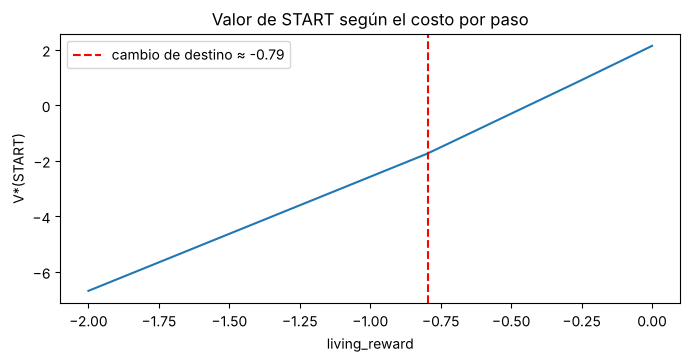

In [9]:
# Bonus: barrido de living_reward para encontrar el cambio de destino desde START
umbrales = np.round(np.arange(-2.0, 0.001, 0.01), 2)
destinos = []
for lr in umbrales:
    g, V, pi = resolver(living_reward=float(lr))
    destinos.append(ruta_desde_start(g, pi)[-1])

for i in range(1, len(umbrales)):
    if destinos[i] != destinos[i - 1]:
        print(f"Cambio entre living_reward = {umbrales[i-1]:.2f} ({destinos[i-1]}) y {umbrales[i]:.2f} ({destinos[i]})")

import matplotlib.pyplot as plt
v_start = [resolver(living_reward=float(lr))[1][(0, 0)] for lr in umbrales]
plt.figure(figsize=(8, 3.5))
plt.plot(umbrales, v_start)
plt.axvline(-0.795, color="red", ls="--", label="cambio de destino ≈ -0.79")
plt.xlabel("living_reward"); plt.ylabel("V*(START)")
plt.title("Valor de START según el costo por paso")
plt.legend(); plt.show()


### Bonus — Respuesta

El destino desde START cambia **entre `living_reward = -0.80` y `-0.79`**:

- con **living_reward ≤ −0.80** el robot va a la **carga +2**;
- con **living_reward ≥ −0.79** intenta llegar a la **entrega +10**.

Es decir, el umbral está en **≈ −0.79**. A partir de ese costo por paso, los 3 pasos adicionales del camino largo (7 frente a 4), sumados al riesgo del peligro −3 en (1,4) y al descuento γ = 0.9, ya no compensan la diferencia de 8 puntos entre +10 y +2. El valor del peligro (−3) y el de las celdas resbalosas se mantuvieron fijos en este barrido.
